# Cooling of a cup of coffee

This notebook revisits the coffee cup example from the lecture notes (Chapter 2), this time using real measurements. Newton's law of cooling says that the temperature $T(t)$ of the coffee changes at a rate proportional to the difference between the coffee temperature and the ambient temperature $\bar{T}$:

$$
\frac{\mathrm{d}}{\mathrm{d}t} T(t) = -k \left( T(t) - \bar{T} \right),
$$

where $k > 0$ is the cooling constant. If the coffee has temperature $T_0$ at time $t_0$, the solution is

$$
T(t) = \left( T_0 - \bar{T} \right) e^{-k (t - t_0)} + \bar{T}.
$$

We will use some measured temperatures to:

1. check that the data really looks like an exponential decay towards $\bar{T}$,
2. estimate the cooling constant $k$,
3. work out when the coffee was brewed, and
4. work out when it will be cool enough to drink.

We start by loading the Python packages we need. You may need to install some of the packages first, e.g. using `pip install numpy matplotlib scipy`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## The data

The temperature of the coffee was measured with a thermometer at several times. The array `t` contains the times $t_n$ (in minutes) and the array `T` the corresponding temperatures $T_n$ (in °C). In Python, arrays are indexed from zero, so `t[0]` is the first measurement time and `T[0]` the temperature at that time.

In [2]:
# Add your data here: t is the time in minutes, T is the temperature in Celsius
t = np.array([5, 10, 15, 20, 25], dtype=float)
T = np.array([85.5, 74.3, 68.3, 61.2, 57.3])

## Does the data follow Newton's law of cooling?

The solution above says that $T(t) - \bar{T}$ decays exponentially, so we expect the data to follow a curve of the form

$$
T(t) = a e^{-k t} + \bar{T},
$$

for some constants $a$ and $k$. Here we take the ambient temperature to be $\bar{T} = 24$ °C. The cell below finds the values of $a$ and $k$ that best fit the data, and plots the data, the fitted curve and the ambient temperature together. You don't need to know how the fit is done. The point is just to see that an exponential decay towards $\bar{T}$ describes the measurements well.

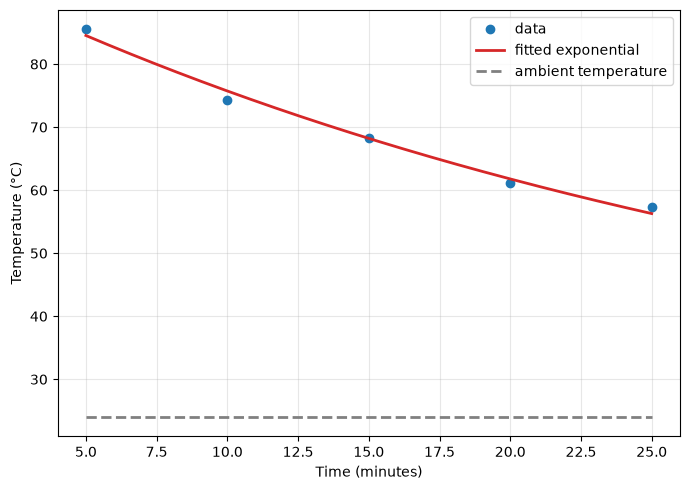

In [3]:
# Fit an exponential to the data. You do not need to know about that, this is simply to show that the data follows an exponential decay.

T_bar = 24
model = lambda x, a, k: a * np.exp(-k * x) + T_bar

popt, pcov = curve_fit(model, t, T, p0=[140, -0.03])
a, k = popt
perr = np.sqrt(np.diag(pcov))

resid = T - model(t, *popt)
r2 = 1 - np.sum(resid**2) / np.sum((T - T.mean())**2)

# print(f"a = {a:.2f} ± {perr[0]:.2f}")
# print(f"k = {k:.5f} ± {perr[1]:.5f}")
# print(f"R² = {r2:.4f}, RMSE = {np.sqrt(np.mean(resid**2)):.3f}")

# Plot
xx = np.linspace(t[0], t[-1], 300)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(t, T, "o", color="tab:blue", label="data")
ax.plot(xx, model(xx, *popt), "-", color="tab:red", lw=2,
        label="fitted exponential")
ax.plot(xx, T_bar * np.ones_like(xx), "--", color="gray", lw=2, label="ambient temperature")
ax.set_xlabel("Time (minutes)")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Estimating the cooling constant $k$

We can estimate $k$ by hand from just two measurements, $(t_i, T_i)$ and $(t_j, T_j)$. Taking the first one as the initial condition ($t_0 = t_i$, $T_0 = T_i$), the solution evaluated at $t_j$ gives

$$
T_j - \bar{T} = \left( T_i - \bar{T} \right) e^{-k (t_j - t_i)}.
$$

Solving for $k$,

$$
k = -\frac{1}{t_j - t_i} \log \left( \frac{T_j - \bar{T}}{T_i - \bar{T}} \right).
$$

Choose the indices `i` and `j` of the two measurements below. Try different pairs and see how much the estimate of $k$ changes.

In [4]:
# Choose which two points to use for the secant line
i = 2
j = 3

# Now we compute k, the cooling constant
k = -np.log((T[j] - T_bar) / (T[i] - T_bar)) / (t[j] - t[i])

print(f"Cooling constant k = {k:.5f} min⁻¹")

Cooling constant k = 0.03494 min⁻¹


Let us check how good this estimate is by plotting the solution with the value of $k$ we have just calculated against the data.

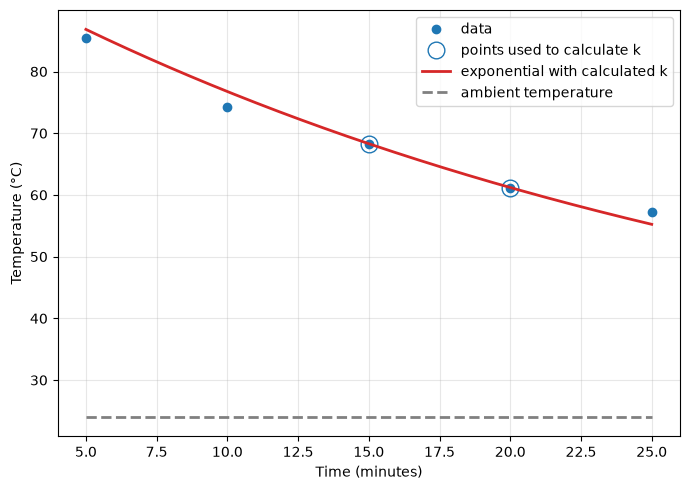

In [5]:
# Initial condition: the first of the two points used to calculate k
t_0 = t[i]
T_0 = T[i]

# Solution of Newton's law of cooling with the calculated k
solution = lambda x: (T_0 - T_bar) * np.exp(-k * (x - t_0)) + T_bar

# Plot
xx = np.linspace(t[0], t[-1], 300)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(t, T, "o", color="tab:blue", label="data")
ax.plot(t[[i, j]], T[[i, j]], "o", color="tab:blue", markersize=12,
        markerfacecolor="none", label="points used to calculate k")
ax.plot(xx, solution(xx), "-", color="tab:red", lw=2,
        label="exponential with calculated k")
ax.plot(xx, T_bar * np.ones_like(xx), "--", color="gray", lw=2, label="ambient temperature")
ax.set_xlabel("Time (minutes)")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## When was the coffee brewed?

Now that we know $k$, we can run the model backwards in time. Assume the coffee was brewed at a temperature of 90 °C. We want the time $t$ at which $T(t) = 90$ °C. Using the measurement $(t_i, T_i)$ as the initial condition,

$$
90 - \bar{T} = \left( T_i - \bar{T} \right) e^{-k (t - t_i)}
\quad \implies \quad
t = t_i - \frac{1}{k} \log \left( \frac{90 - \bar{T}}{T_i - \bar{T}} \right).
$$

Since the coffee was hotter than $T_i$ when it was brewed, the logarithm is positive and this time is earlier than $t_i$, as expected.

In [6]:
# When did I brew my coffee?
T_brew = 90 # Temperature of freshly brewed coffee in Celsius
t_brew = t_0 - np.log((T_brew - T_bar) / (T_0 - T_bar)) / k

print(f"Time of brewing: {t_brew:.2f} minutes")

Time of brewing: 3.59 minutes


## When can I drink the coffee?

Finally, as in the lecture notes, we want the time $t^*$ at which the coffee has cooled down to a drinkable temperature $T^* = 50$ °C. The same calculation, now with $T(t^*) = T^*$, gives

$$
t^* = t_i - \frac{1}{k} \log \left( \frac{T^* - \bar{T}}{T_i - \bar{T}} \right).
$$

Since $\bar{T} < T^* < T_i$, the logarithm is negative and $t^*$ is later than $t_i$. Compare the prediction with the measurements: when does the measured temperature actually drop to about 50 °C?

In [7]:
# When can I drink my coffee?
T_drink = 50 # Temperature of coffee when it's ready to drink in Celsius
t_drink = t_0 - np.log((T_drink - T_bar) / (T_0 - T_bar)) / k

print(f"Time to drink: {t_drink:.2f} minutes")

Time to drink: 30.25 minutes
